# 1. Definition: Z-Score Normalization (Standardization)

While the Z-score formula is the same as outlier detection, its **goal** changes. In data normalization, the Z-score is used to rescale features so that the entire dataset has a **mean ($\mu$) of 0** and a **standard deviation ($\sigma$) of 1**.

**The Formula:**

$$X_{scaled} = \frac{(X - \mu)}{\sigma}$$

**Note on Terminology:** In statistics, this is strictly called *Standardization*. In Machine Learning, "Normalization" and "Standardization" are often used interchangeably, though "Normalization" technically refers to Min-Max scaling (scaling to a 0–1 range).

---

# 2. Why Use Z-Score Standardization?

Machine learning algorithms that rely on **distance calculations** or **gradient descent** are highly sensitive to the scale of the data.

* **Distance-Based Algorithms:** K-Nearest Neighbors (KNN), Support Vector Machines (SVM), and K-Means Clustering calculate the distance between data points. If one feature is measured in thousands (e.g., Salary: $50,000) and another in single digits (e.g., Age: 30), the larger feature will completely dominate the distance calculation.
* **Gradient Descent Algorithms:** Linear Regression, Logistic Regression, and Neural Networks converge much faster and more reliably when features are on the same scale, preventing the loss landscape from becoming elongated and difficult to navigate.
* **Principal Component Analysis (PCA):** PCA is variance-based. Without standardization, features with larger numerical ranges will artificially appear to have higher variance and dominate the principal components.

---

# 3. Z-Score vs. Min-Max Scaling

| Feature | Z-Score (Standardization) | Min-Max Scaling (Normalization) |
| :--- | :--- | :--- |
| **Formula** | $\frac{(X - \mu)}{\sigma}$ | $\frac{(X - X_{min})}{(X_{max} - X_{min})}$ |
| **Resulting Range** | No fixed range (typically -3 to +3) | Fixed range, usually [0, 1] or [-1, 1] |
| **Effect on Outliers** | Preserves outliers (they remain far from 0) | Compresses outliers (squashes normal data into a tiny range) |
| **Best Used For** | Algorithms assuming normal distribution (Linear Regression, PCA, Neural Networks) | Algorithms requiring strict bounded inputs (Image pixel data, certain Neural Network activation functions) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

# Create a dataset with wildly different scales
np.random.seed(42)
df = pd.DataFrame({
    'Age': np.random.randint(20, 60, 100),          # Scale: 20 - 60
    'Annual_Income': np.random.randint(30000, 120000, 100), # Scale: 30k - 120k
    'Credit_Score': np.random.randint(300, 850, 100)        # Scale: 300 - 850
})

print("Original Data Statistics:")
display(df.describe().round(2))

Original Data Statistics:


,Age,Annual_Income,Credit_Score
count,100.00,100.00,100.00
mean,38.79,78526.89,564.39
std,11.56,25930.44,154.85
min,20.00,30206.00,301.00
25%,28.00,55789.75,445.25
50%,39.50,81544.00,553.00
75%,47.25,98107.25,700.50
max,59.00,119474.00,846.00


In [2]:
# Method A

# Manual Z-score standardization
df_manual = df.copy()
df_manual['Age_Z'] = (df_manual['Age'] - df_manual['Age'].mean()) / df_manual['Age'].std()
df_manual['Income_Z'] = (df_manual['Annual_Income'] - df_manual['Annual_Income'].mean()) / df_manual['Annual_Income'].std()
df_manual['Credit_Z'] = (df_manual['Credit_Score'] - df_manual['Credit_Score'].mean()) / df_manual['Credit_Score'].std()

print("Manual Standardization Statistics (Mean should be ~0, Std should be ~1):")
display(df_manual[['Age_Z', 'Income_Z', 'Credit_Z']].describe().round(2))

Manual Standardization Statistics (Mean should be ~0, Std should be ~1):


,Age_Z,Income_Z,Credit_Z
count,100.00,100.00,100.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.63,-1.86,-1.70
25%,-0.93,-0.88,-0.77
50%,0.06,0.12,-0.07
75%,0.73,0.76,0.88
max,1.75,1.58,1.82


In [3]:
# Method B - Scikit-Learn StandardScaler (Industry Standard)
# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the data (returns a numpy array, so we convert back to DataFrame)
df_scaled = pd.DataFrame(
    scaler.fit_transform(df), 
    columns=[f"{col}_Scaled" for col in df.columns],
    index=df.index
)

print("Scikit-Learn Standardization Statistics:")
display(df_scaled.describe().round(2))

Scikit-Learn Standardization Statistics:


,Age_Scaled,Annual_Income_Scaled,Credit_Score_Scaled
count,100.00,100.00,100.00
mean,0.00,0.00,0.00
std,1.01,1.01,1.01
min,-1.63,-1.87,-1.71
25%,-0.94,-0.88,-0.77
50%,0.06,0.12,-0.07
75%,0.74,0.76,0.88
max,1.76,1.59,1.83


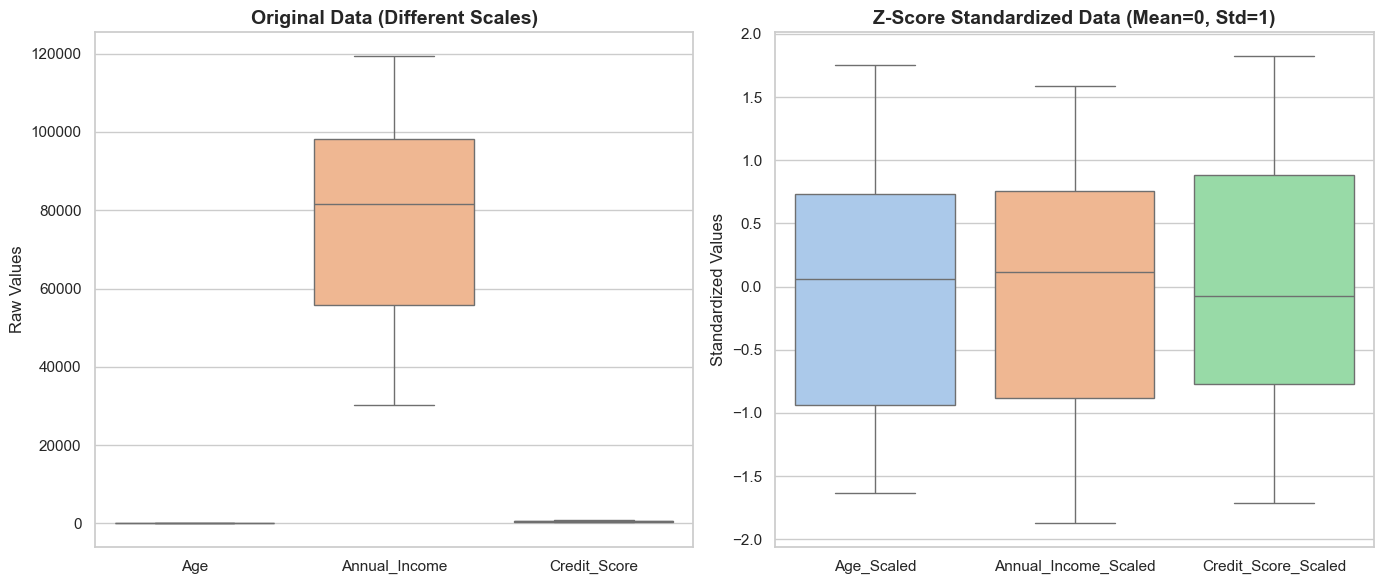

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Original Data (Notice the wildly different x-axis scales)
sns.boxplot(data=df, ax=axes[0], palette="pastel")
axes[0].set_title('Original Data (Different Scales)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Raw Values')

# Plot 2: Scaled Data (Notice all features now center around 0)
sns.boxplot(data=df_scaled, ax=axes[1], palette="pastel")
axes[1].set_title('Z-Score Standardized Data (Mean=0, Std=1)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Standardized Values')

plt.tight_layout()
plt.show()